### Task 1: EDA in Retail Sales Dataset

#### Objectives: To perform a thorough Exploratory Data Analysis on a retail sale dataset to uncover patterns, customer behaviour trends, and actionable  business insights.

In [3]:
# importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Load the dataset

df = pd.read_csv("C:/Users/PROGRESSIVE/Desktop/EXCEL/ecommerce_customer_behavior_dataset.csv")
df.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4


In [61]:
def inspect_dataframe(df):
    """
    Inspecting Dataframe.
    """
    print(f"Rows: {df.shape[0]}")
    print(f"Columnss: {df.shape[1]}")

    print(f"\nData Types")
    display(df.dtypes)

    print(f"\nData Info")
    display(df.info())

    print(f"\nNull Value Check")
    display(df.isnull().sum())




In [62]:
inspect_dataframe(df)

Rows: 5000
Columnss: 23

Data Types


Order_ID                               str
Customer_ID                            str
Date                        datetime64[us]
Age                                  int64
Gender                                 str
City                                   str
Product_Category                       str
Unit_Price                         float64
Quantity                             int64
Discount_Amount                    float64
Total_Amount                       float64
Payment_Method                         str
Device_Type                            str
Session_Duration_Minutes             int64
Pages_Viewed                         int64
Is_Returning_Customer                 bool
Delivery_Time_Days                   int64
Customer_Rating                      int64
Month                                  str
Quarter                              int32
Year_Month                             str
Year_Quarter                           str
Age_Group                         category
dtype: obje


Data Info
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order_ID                  5000 non-null   str           
 1   Customer_ID               5000 non-null   str           
 2   Date                      5000 non-null   datetime64[us]
 3   Age                       5000 non-null   int64         
 4   Gender                    5000 non-null   str           
 5   City                      5000 non-null   str           
 6   Product_Category          5000 non-null   str           
 7   Unit_Price                5000 non-null   float64       
 8   Quantity                  5000 non-null   int64         
 9   Discount_Amount           5000 non-null   float64       
 10  Total_Amount              5000 non-null   float64       
 11  Payment_Method            5000 non-null   str           
 12  Device_Type         

None


Null Value Check


Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
Month                       0
Quarter                     0
Year_Month                  0
Year_Quarter                0
Age_Group                   0
dtype: int64

## 2. Descriptive Statistics

**Goal:** Summarise the numerical columns using the mean, median, mode, and standard deviation.

**Method:** I selected the numerical columns and calculated the four statistics for each. I left out the `Quarter` column I created earlier, because it is a label (1 to 4) and not a real measurement.

- **Mean:** the average value.
- **Median:** the middle value, which is less affected by extreme values.
- **Mode:** the most common value.
- **Standard deviation:** how spread out the values are around the mean.

In [60]:
# Pick the numerical columns, leaving out Quarter (it's a label, not a measurement)
num_df = df.select_dtypes(include="number").drop(columns=["Quarter"], errors="ignore")

# Build one table with the four statistics the task asks for
stats = pd.DataFrame({
    "Mean": num_df.mean(),
    "Median": num_df.median(),
    "Mode": num_df.mode().iloc[0],
    "Std Dev": num_df.std()
}).round(2)

print(stats)

                            Mean  Median   Mode  Std Dev
Age                        35.03   35.00  18.00    11.08
Unit_Price                455.83  182.95  30.10   712.48
Quantity                    2.22    2.00   1.00     1.40
Discount_Amount            24.85    0.00   0.00    88.39
Total_Amount              983.11  337.91  23.05  1898.98
Session_Duration_Minutes   14.57   13.00   9.00     8.67
Pages_Viewed                8.98    9.00   8.00     2.80
Delivery_Time_Days          6.50    6.00   5.00     3.46
Customer_Rating             3.90    4.00   5.00     1.13


### Descriptive Statistics

- The dataset has **5,000 transactions** with no missing values in the numerical columns.
- **Sales are right-skewed.** The average `Total_Amount` is about **983 TRY**, but the median is only about **338 TRY**, and the standard deviation (about 1,899 TRY) is larger than the mean. A few very expensive purchases pull the average up, so the median is a better picture of a typical transaction. `Unit_Price` shows the same pattern (mean about 456 TRY, median about 183 TRY).
- **Most purchases have no discount.** The median and mode of `Discount_Amount` are both **0**, while the mean is about 24.85 TRY because a few large discounts raise it.
- **Customer age** is centred around **35** (mean 35.03, median 35). The most common single age is **18**, but the spread is wide (standard deviation about 11).
- **Quantity** per transaction is small: the most common purchase is **1 unit**, and the average is about **2.2** units.
- **Customer ratings** average about **3.9 out of 5** (median 4), and the most common rating is **5**. Most customers are satisfied, with a smaller group giving lower scores that pull the average down.
- **Sessions** are short: customers spend about **14.6 minutes** on the site on average and view about **9 pages**.
- **Delivery** takes about **6.5 days** on average (median 6, most common 5 days).
- The mode of `Unit_Price` (30.10 TRY) and `Total_Amount` (23.05 TRY) is the single most repeated value. For money columns with many different values, the median describes a typical transaction better.

### 2. Time series analysis

Sales Trends Over Time
Goal: Find out how total sales changed month by month and quarter by quarter.

Method: I converted the Date column to a datetime type, then created Year_Month and Year_Quarter columns. I included the year so that, for example, January 2023 and January 2024 are not combined. I then added up Total_Amount for each period and plotted it as a line chart.

Note: The dataset covers January 2023 to March 2024, so there are 15 months and 5 quarters. All amounts are in Turkish Lira (TRY).

In [11]:
# Check date column data type
df['Date'].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
# Convert the column to datetime

df['Date'] = pd.to_datetime(df['Date'])

In [19]:
# Verif the conversion

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order_ID                  5000 non-null   str           
 1   Customer_ID               5000 non-null   str           
 2   Date                      5000 non-null   datetime64[us]
 3   Age                       5000 non-null   int64         
 4   Gender                    5000 non-null   str           
 5   City                      5000 non-null   str           
 6   Product_Category          5000 non-null   str           
 7   Unit_Price                5000 non-null   float64       
 8   Quantity                  5000 non-null   int64         
 9   Discount_Amount           5000 non-null   float64       
 10  Total_Amount              5000 non-null   float64       
 11  Payment_Method            5000 non-null   str           
 12  Device_Type               5000 

In [17]:
print(df["Date"].min(), df["Date"].max())

2023-01-01 00:00:00 2024-03-26 00:00:00


In [18]:
# Changing the data column to monthly & quartely

df['Month'] = df['Date'].dt.month_name()
df['Quarter'] = df['Date'].dt.quarter

In [20]:
# Checking the number of year

df["Date"].dt.year.unique()

array([2023, 2024], dtype=int32)

In [21]:
# A new column that include year

df["Year_Month"] = df["Date"].dt.to_period("M").astype(str)
df["Year_Quarter"] = df["Date"].dt.to_period("Q").astype(str)

In [22]:
df["Year_Month"].head()
df["Year_Month"].nunique()   

15

## Sales Trends Over Time

**Goal:** Find out how total sales changed month by month and quarter by quarter.

**Method:** I converted the `Date` column to a datetime type, then created `Year_Month` and `Year_Quarter` columns. I included the year so that, for example, January 2023 and January 2024 are not combined. I then added up `Total_Amount` for each period and plotted it as a line chart.

**Note:** The dataset covers January 2023 to March 2024, so there are 15 months and 5 quarters. All amounts are in Turkish Lira (TRY).

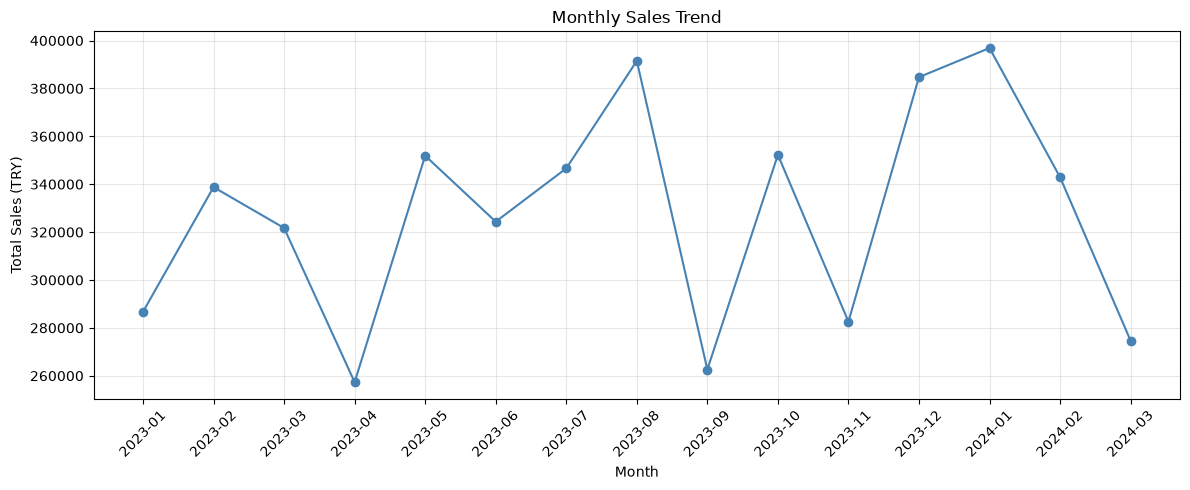

In [25]:
monthly_sales = df.groupby("Year_Month")["Total_Amount"].sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_sales.index, monthly_sales.values, marker="o", color="steelblue")
ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales (TRY)")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Sales Trend: What I See

- Monthly sales change a lot, ranging from about **257,000 TRY** (April 2023, the lowest) to about **397,000 TRY** (January 2024, the highest).
- Other strong months are **August 2023** (about 391,000) and **December 2023** (about 385,000).
- Weak months are **April 2023** and **September 2023** (about 262,000).
- Sales rise and fall in a zig-zag pattern instead of moving in a straight line, but the higher peaks later in the period suggest a slight upward trend.
- **March 2024** looks low (about 274,000), but the data ends on 2024-03-26 **(26, March 2024)**, so the month is incomplete and should not be read as a real decline.

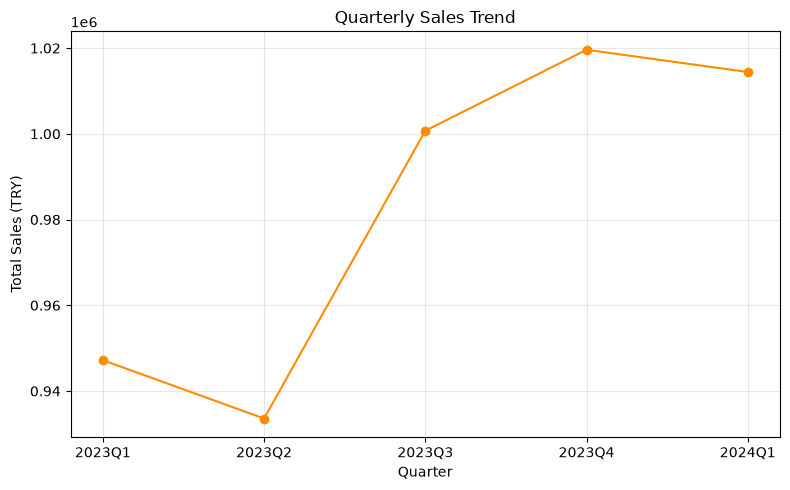

In [26]:
quarterly_sales = df.groupby("Year_Quarter")["Total_Amount"].sum()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(quarterly_sales.index, quarterly_sales.values, marker="o", color="darkorange")
ax.set_title("Quarterly Sales Trend")
ax.set_xlabel("Quarter")
ax.set_ylabel("Total Sales (TRY)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Quarterly Sales Trend: What I See

- **2023 Q2** was the weakest quarter (about 933,000 TRY).
- Sales then rose in **Q3** (about 1.00 million TRY) and peaked in **2023 Q4** (about 1.02 million TRY).
- **2024 Q1** (about 1.01 million TRY) stayed close to the Q4 peak even tough the quarter is incomplete
- Overall, sales grew about 9% from the Q2 low to the Q4 peak. The chart's y-axis does not start at zero, so the rise looks steeper than it is.

### Key Takeaways

1. Sales are higher in the second half of the period than in the first.
2. The strongest months are January 2024, August 2023, and December 2023, which may point to end-of-year and summer demand.
3. April and September 2023 were the weakest months, so these are good times for promotions.
4. The data suggests a modest upward trend, but with only 15 months of data I cannot say whether the pattern repeats every year.

## 4. Customer Demographics

**Goal:** Understand who the customers are by looking at the distribution of customer age groups and the gender breakdown.

**Note:** Customer ages in this dataset range from 18 to 75. The dataset contains 5,000 transactions.

In [28]:
# Checking the age range

print(df["Age"].min(), df["Age"].max())
df["Gender"].value_counts()

18 75


Gender
Female    2492
Male      2435
Other       73
Name: count, dtype: int64

In [42]:
age_counts = df["Age_Group"].value_counts().sort_index()
age_pct = df["Age_Group"].value_counts(normalize=True).sort_index() * 100

age_summary = pd.DataFrame({
    "Count": age_counts,
    "Percentage": age_pct.round(2)
})
print(age_summary)

           Count  Percentage
Age_Group                   
18-25       1125       22.50
26-35       1514       30.28
36-45       1470       29.40
46-55        697       13.94
56-65        171        3.42
66+           23        0.46


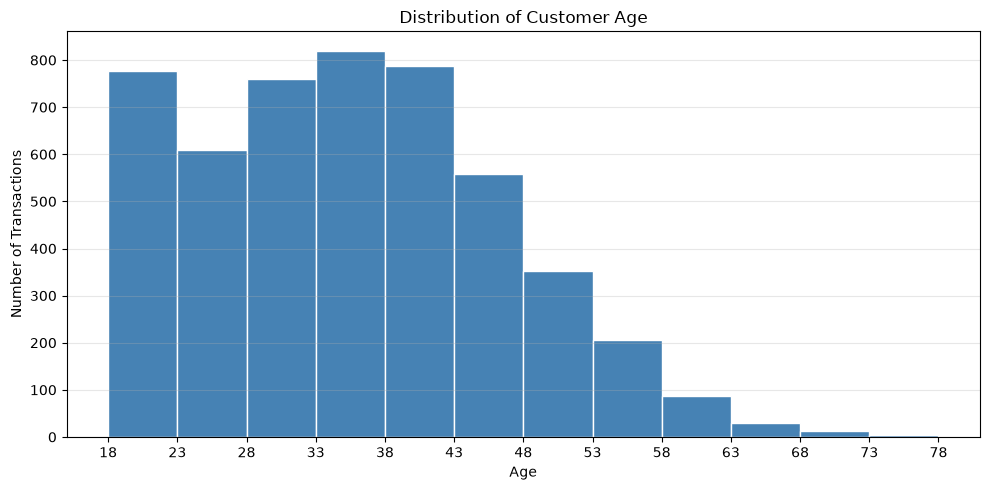

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["Age"], bins=range(18, 79, 5), color="steelblue", edgecolor="white")
ax.set_title("Distribution of Customer Age")
ax.set_xlabel("Age")
ax.set_ylabel("Number of Transactions")
ax.set_xticks(range(18, 79, 5))
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Age Distribution: What I See

- Customer activity is high and fairly steady from ages **18 to about 43**, with roughly 600 to 800 transactions in each 5-year band.
- The peak is at ages **33-37** (about 820 transactions).
- Transactions fall steadily after the early 40s and become very rare above 60.
- The small dip at ages 23-27 looks like normal variation and not a real pattern.

In [39]:
gender_counts = df["Gender"].value_counts()
gender_pct = df["Gender"].value_counts(normalize=True) * 100

gender_summary = pd.DataFrame({
    "Count": gender_counts,
    "Percentage": gender_pct.round(2)
})
print(gender_summary)

        Count  Percentage
Gender                   
Female   2492       49.84
Male     2435       48.70
Other      73        1.46


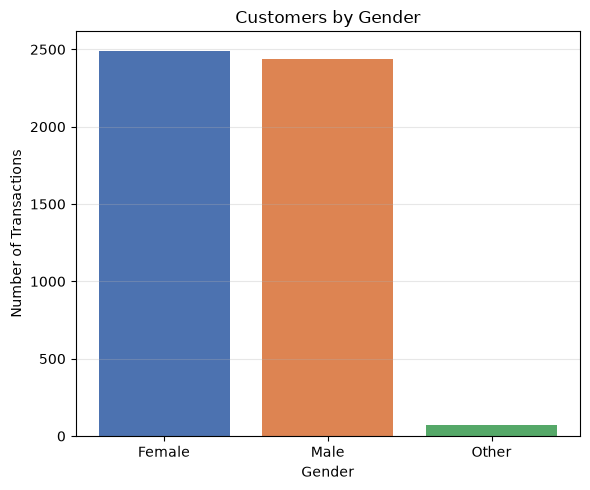

In [38]:
gender_counts = df["Gender"].value_counts()

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(gender_counts.index, gender_counts.values, color=["#4C72B0", "#DD8452", "#55A868"][:len(gender_counts)])
ax.set_title("Customers by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of Transactions")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Gender Breakdown

- The customer base is almost evenly split between **female (49.84%)** and **male (48.70%)** customers, a gap of only about 1 percentage point.
- Customers who identify as **Other** make up only **1.46%** (73 of 5,000 transactions).
- Because the female and male shares are so close, gender alone does not separate the customers much.
- Results for the "Other" group should be read with care, since it is based on very few transactions.

## 5. Product Analysis

**Goal:** Find out which product categories bring in the most revenue.

**Method:** I added up `Total_Amount` (the final amount paid after discounts) for each product category and plotted the totals as a bar chart, sorted from highest to lowest.

**Note:** This dataset has product categories but no individual product names, so the "top 10 best-selling products" analysis could not be done as written. I ranked the 8 product categories by revenue instead.

In [50]:
df["Product_Category"].value_counts()

Product_Category
Sports           667
Electronics      624
Fashion          622
Beauty           621
Home & Garden    621
Food             619
Books            616
Toys             610
Name: count, dtype: int64

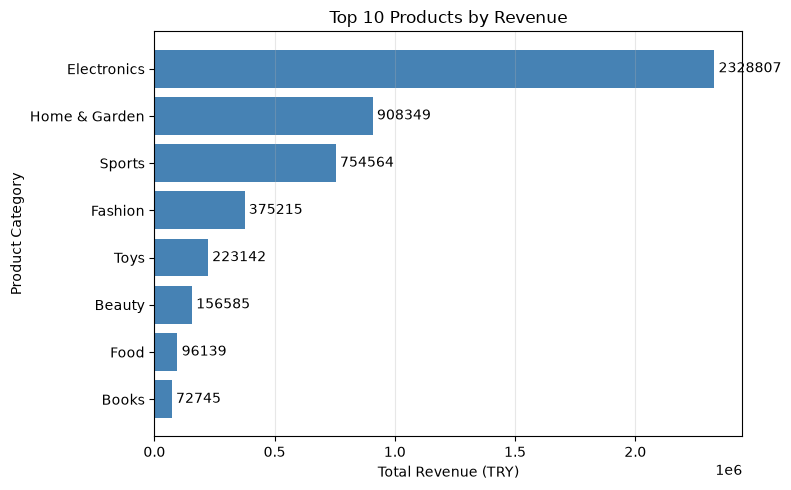

In [47]:
top_products = (df.groupby("Product_Category")["Total_Amount"]
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top_products.index[::-1], top_products.values[::-1], color="steelblue")
ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Total Revenue (TRY)")
ax.set_ylabel("Product Category")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
category_revenue = df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
category_pct = category_revenue / category_revenue.sum() * 100

category_summary = pd.DataFrame({
    "Revenue (TRY)": category_revenue,
    "Percentage": category_pct.round(2)
})
category_summary["Cumulative %"] = (category_pct.cumsum()).round(2)
print(category_summary)

                  Revenue (TRY)  Percentage  Cumulative %
Product_Category                                         
Electronics          2328806.81       47.38         47.38
Home & Garden         908348.86       18.48         65.86
Sports                754563.56       15.35         81.21
Fashion               375214.93        7.63         88.84
Toys                  223142.48        4.54         93.38
Beauty                156584.74        3.19         96.56
Food                   96138.67        1.96         98.52
Books                  72744.52        1.48        100.00


### Revenue by Product Category

- **Electronics** is by far the biggest revenue driver at **2,328,807 TRY**, which is **47.38%** of all revenue. That is about 2.6 times the next category.
- **Home & Garden** (**18.48%**) and **Sports** (**15.35%**) come next. The cumulative percentage shows that these top three categories together bring in **81.21%** of total revenue. In other words, 3 of the 8 categories produce over 80% of sales.
- **Fashion** (**7.63%**), **Toys** (**4.54%**), and **Beauty** (**3.19%**) are mid-to-low earners.
- **Food** (**1.96%**) and **Books** (**1.48%**) contribute the least.
- Revenue depends heavily on one category, so sales are exposed to anything that affects Electronics demand.

## 6. Correlation Analysis

**Goal:** Find out which numerical variables are related to each other.

**Variables included:** All 9 numerical columns in the dataset: `Age`, `Unit_Price`, `Quantity`, `Discount_Amount`, `Total_Amount`, `Session_Duration_Minutes`, `Pages_Viewed`, `Delivery_Time_Days`, and `Customer_Rating`. I excluded the `Quarter` column I created earlier, because it is a label (1 to 4) and not a real measurement.

**Method:** I calculated the correlation between every pair of these variables and plotted the result as a heatmap. Values run from -1 to 1:
- Close to **1**: the two variables increase together.
- Close to **-1**: one increases as the other decreases.
- Close to **0**: little or no linear relationship.

In [63]:
num_df = df.select_dtypes(include="number").drop(columns=["Quarter"], errors="ignore")

print("Numerical variables used for correlation:")
print(num_df.columns.tolist())
print("Number of variables:", num_df.shape[1])

Numerical variables used for correlation:
['Age', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Session_Duration_Minutes', 'Pages_Viewed', 'Delivery_Time_Days', 'Customer_Rating']
Number of variables: 9


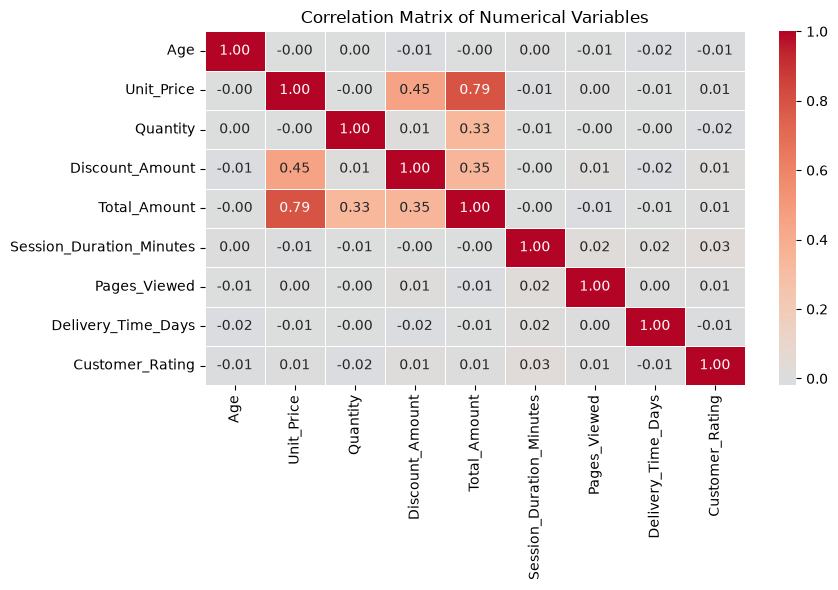

In [73]:
corr = num_df.corr()

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

### Correlation Heatmap

- **Unit_Price and Total_Amount (0.79)** have the strongest relationship. Transactions for higher-priced items are larger, which is expected.
- **Unit_Price and Discount_Amount (0.45)** and **Discount_Amount and Total_Amount (0.35)** show moderate positive relationships. Discounts tend to be larger on expensive, high-value purchases, probably because they are calculated from the purchase value. This does not show that discounts cause larger sales.
- **Quantity and Total_Amount (0.33)** is a weaker link. Price per unit matters more than the number of units for the size of a transaction.
- **Customer behaviour and satisfaction variables are essentially unrelated** to everything else (all values between about -0.02 and 0.03): `Age`, `Session_Duration_Minutes`, `Pages_Viewed`, `Delivery_Time_Days`, and `Customer_Rating`.
- In particular, **delivery time does not affect customer rating** (-0.01), and **age does not affect spending** (0.00).
- Correlation only measures straight-line relationships and does not prove cause and effect.

## 7. Additional Visualisation: Average Spend by Category

**Goal:** Find out whether a category's revenue comes from many purchases or from expensive ones.

**Method:** I calculated the number of transactions and the average spend per transaction for each product category, and plotted the average spend.

In [74]:
category_stats = df.groupby("Product_Category").agg(
    Transactions=("Total_Amount", "count"),
    Avg_Spend=("Total_Amount", "mean")
).sort_values("Avg_Spend", ascending=False).round(2)

print(category_stats)

                  Transactions  Avg_Spend
Product_Category                         
Electronics                624    3732.06
Home & Garden              621    1462.72
Sports                     667    1131.28
Fashion                    622     603.24
Toys                       610     365.81
Beauty                     621     252.15
Food                       619     155.31
Books                      616     118.09


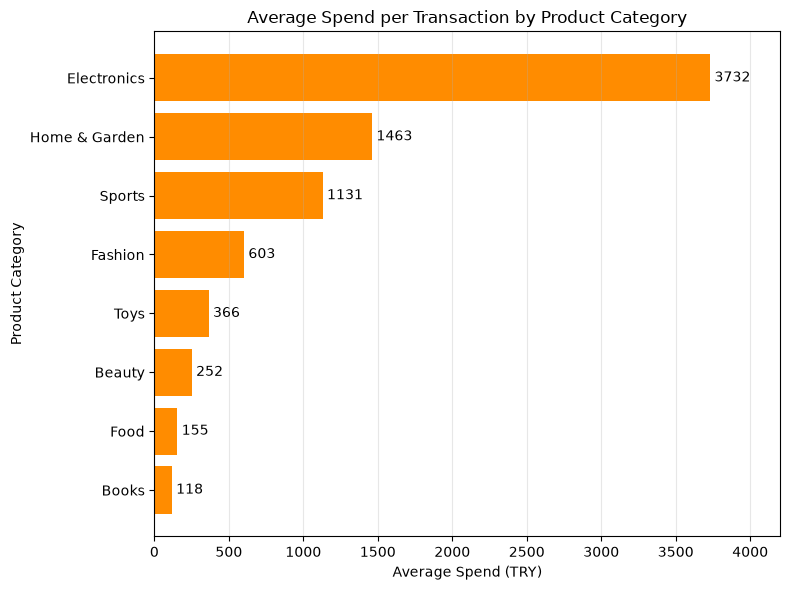

In [82]:
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(category_stats.index, category_stats["Avg_Spend"], color="darkorange")
ax.invert_yaxis()
ax.set_title("Average Spend per Transaction by Product Category")
ax.set_xlabel("Average Spend (TRY)")
ax.set_ylabel("Product Category")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.grid(True, axis="x", alpha=0.3)
ax.set_xlim(0, 4200)
plt.tight_layout()
plt.show()

### Average Spend per Transaction by Category

- Every category has a **similar number of transactions** (between about 610 and 667), so customers buy from all categories at about the same rate. Electronics (624) is not the most frequently bought category. **Sports** is (667).
- The big difference is in **how much each purchase is worth**. The average Electronics purchase is about **3,732 TRY**, compared with about **1,463 TRY** for Home & Garden, **1,131 TRY** for Sports, and only **118 TRY** for Books.
- This explains the revenue ranking from the product analysis: **Electronics leads because of high prices per purchase, not because more people buy it.**
- **Sports** has the most transactions but ranks third in revenue, because the average purchase is small. **Books** and **Food** are bought as often as any other category but contribute very little revenue.

## 8. Conclusion and Recommendations

### Summary of Findings

- **Sales trend:** Monthly sales ranged from about 257,000 TRY (April 2023) to about 397,000 TRY (January 2024), with peaks in August 2023, December 2023, and January 2024. The weakest months were April and September 2023.
- **Customers:** About **82%** of transactions come from customers aged **18-45**, and the **26-35** group is the largest (30.28%). Customers over 55 make up under 4%. Male and female customers are almost evenly split (48.70% and 49.84%).
- **Products:** **Electronics** brings in **47.38%** of revenue, and the top three categories (Electronics, Home & Garden, Sports) bring in **81.21%**.
- **Why Electronics leads:** All categories have a similar number of transactions (about 610 to 667), but the average Electronics purchase is about **3,732 TRY**, compared with about **118 TRY** for Books.
- **Relationships:** Total amount is strongly linked to unit price (0.79). Age, delivery time, session length, and pages viewed show almost no relationship with spending or customer rating.

### Recommendations

1. **Prioritise Electronics in stock and marketing, and reduce the dependence on it.**
   Electronics earns almost half of all revenue from the same number of purchases as every other category, so keeping it well stocked and promoted protects the most revenue. Because so much rests on one category, the business should also track its sales closely and avoid letting Electronics stock-outs or price changes hit total revenue.

2. **Focus marketing on customers aged 18-45, especially 26-35.**
   This group makes about 82% of all purchases. Campaigns, ads, and product selection should be built around their needs. Customers over 55 account for under 4% of transactions, so spending heavily to reach them is not supported by this data.

3. **Run promotions in the weak months and prepare stock for the peaks.**
   Sales were lowest in April and September 2023, so these are good times to test promotions or discounts. Sales were highest in August, December, and January, so stock and staffing should be ready before those months. With only 15 months of data, the pattern should be confirmed with a full second year before the business relies on it.

4. **Raise the value of low-spend categories through bundling and upselling.**
   Sports is bought most often (667 transactions) but ranks third in revenue because the average purchase is small (about 1,131 TRY). Books and Food are bought as often as any other category but average only about 118 TRY and 155 TRY. Bundling these with higher-value purchases, or offering premium options within Sports, could increase the value of each order.

5. **Do not target marketing by gender.**
   Male and female customers buy at almost the same rate (48.70% and 49.84%), and the "Other" group is only 1.46%. Targeting by age and category is better supported by the data.

### Limitations

- The dataset has product categories but no individual product names, so the "top 10 best-selling products" analysis was replaced with a ranking of product categories by revenue.
- The data covers only about 15 months, and March 2024 (and therefore Q1 2024) is incomplete because the data ends on 26 March 2024.
- The 66+ age group (23 transactions) and the "Other" gender group (73 transactions) are small, so results for them should be read with care.
- Correlation does not prove cause and effect.